In [1]:
import os
import random
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
import lightgbm as lgb
warnings.filterwarnings("ignore")
print("citations: feature and validation pipeline reuses tutorial.ipynb and tutorial_improved_v1_4.ipynb and tutorial_improved_v2_0.ipynb and tutorial_improved_v2_5.ipynb")
print("v2.6 design: keep v2.5 row features, add LightGBM branch, probe rank plus pruned-groupby plus pair-TE in ablation and keep only measured winners")
SEED = 42
N_SPLITS = 5
SMOOTHING = 60
SEEDS = [42, 43, 44, 45, 46]
CAT8 = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE",
        "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]
RANK_COLS = ["EXT_SOURCE_MEAN", "EXT_SOURCE_MIN", "EXT_SOURCE_MAX", "AGE_YEARS",
             "AMT_CREDIT", "AMT_INCOME_TOTAL", "CREDIT_INCOME_RATIO"]
PRUNE_CATS = ["OCCUPATION_TYPE", "ORGANIZATION_TYPE", "NAME_EDUCATION_TYPE"]
PRUNE_NUMS = ["EXT_SOURCE_MEAN", "AGE_YEARS"]
PAIRS = [("OCCUPATION_TYPE", "ORGANIZATION_TYPE"),
         ("NAME_EDUCATION_TYPE", "OCCUPATION_TYPE")]
HGB_A = dict(learning_rate=0.035, max_iter=700, max_leaf_nodes=31, min_samples_leaf=80, l2_regularization=2.0)
HGB_C = dict(learning_rate=0.03, max_iter=1000, max_leaf_nodes=63, min_samples_leaf=50, l2_regularization=2.0)
LGBM_P = dict(n_estimators=1000, learning_rate=0.02, num_leaves=31, min_child_samples=80,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l1=0.1, lambda_l2=1.0, deterministic=True, verbose=-1)
np.random.seed(SEED)
random.seed(SEED)
print("pandas", pd.__version__, "sklearn", __import__("sklearn").__version__, "lgbm", lgb.__version__)
print("CAT8 =", CAT8)
print("SEEDS =", SEEDS)
print("RANK_COLS =", RANK_COLS)
print("PRUNE_CATS =", PRUNE_CATS, "PRUNE_NUMS =", PRUNE_NUMS)
print("PAIRS =", PAIRS)


citations: feature and validation pipeline reuses tutorial.ipynb and tutorial_improved_v1_4.ipynb and tutorial_improved_v2_0.ipynb and tutorial_improved_v2_5.ipynb
v2.6 design: keep v2.5 row features, add LightGBM branch, probe rank plus pruned-groupby plus pair-TE in ablation and keep only measured winners
pandas 3.0.6 sklearn 1.9.1 lgbm 4.7.0
CAT8 = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
SEEDS = [42, 43, 44, 45, 46]
RANK_COLS = ['EXT_SOURCE_MEAN', 'EXT_SOURCE_MIN', 'EXT_SOURCE_MAX', 'AGE_YEARS', 'AMT_CREDIT', 'AMT_INCOME_TOTAL', 'CREDIT_INCOME_RATIO']
PRUNE_CATS = ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'NAME_EDUCATION_TYPE'] PRUNE_NUMS = ['EXT_SOURCE_MEAN', 'AGE_YEARS']
PAIRS = [('OCCUPATION_TYPE', 'ORGANIZATION_TYPE'), ('NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE')]


In [2]:
current_dir = Path.cwd()
input_dir = current_dir / "input"
train_file = input_dir / "train.csv"
test_file = input_dir / "test.csv"
sample_sub_file = input_dir / "sample_submission.csv"
assert train_file.exists()
assert test_file.exists()
assert sample_sub_file.exists()
train_raw = pd.read_csv(train_file)
test_raw = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
print("train:", train_raw.shape, "test:", test_raw.shape, "sample_sub:", sample_sub.shape)
assert "TARGET" in train_raw.columns and "TARGET" not in test_raw.columns
assert list(sample_sub.columns) == ["SK_ID_CURR", "TARGET"]
assert sample_sub["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
assert len(test_raw) == 61500
y = train_raw["TARGET"].astype(int)
X_raw = train_raw.drop(columns="TARGET")
X_test_raw = test_raw.copy()
print("TARGET mean:", float(y.mean()))
print(y.value_counts().to_string())
print(train_raw.dtypes.value_counts())


train: (171202, 34) test: (61500, 33) sample_sub: (61500, 2)
TARGET mean: 0.08072919708881905
TARGET
0    157381
1     13821
float64    16
int64      10
str         8
Name: count, dtype: int64


Top-15 missing fractions:
EXT_SOURCE_1                  0.694665
OWN_CAR_AGE                   0.659992
EXT_SOURCE_3                  0.318840
AMT_REQ_CREDIT_BUREAU_MON     0.135022
AMT_REQ_CREDIT_BUREAU_QRT     0.135022
AMT_REQ_CREDIT_BUREAU_HOUR    0.135022
AMT_REQ_CREDIT_BUREAU_YEAR    0.135022
EXT_SOURCE_2                  0.002155
CNT_FAM_MEMBERS               0.000012
SK_ID_CURR                    0.000000
NAME_CONTRACT_TYPE            0.000000
CODE_GENDER                   0.000000
AMT_INCOME_TOTAL              0.000000
CNT_CHILDREN                  0.000000
AMT_ANNUITY                   0.000000


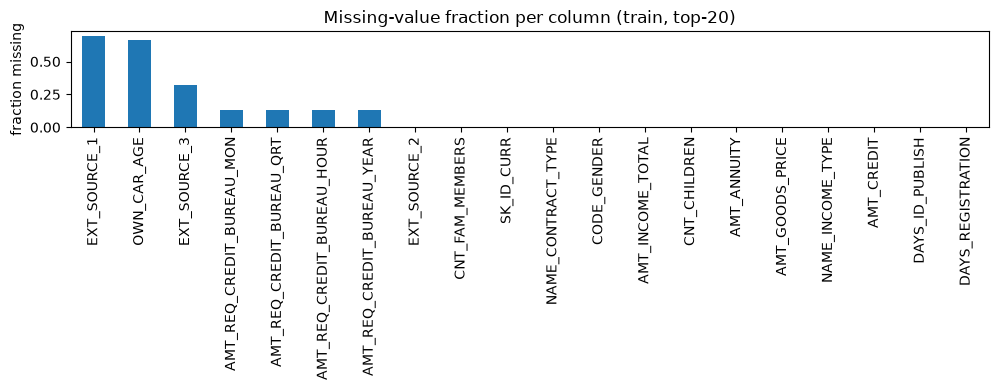

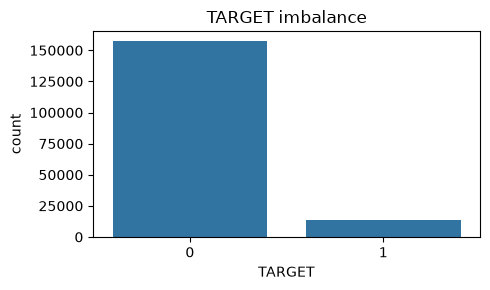

DAYS_EMPLOYED anomaly share train: 0.18047686358804219 test: 0.17178861788617886


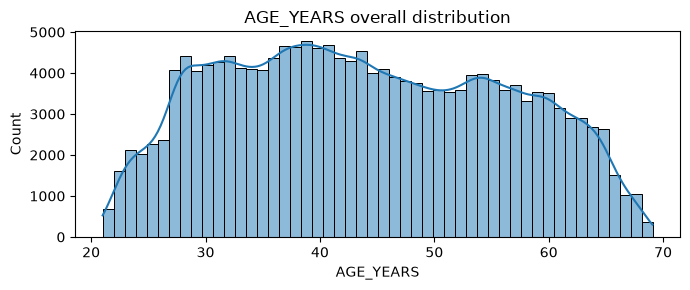

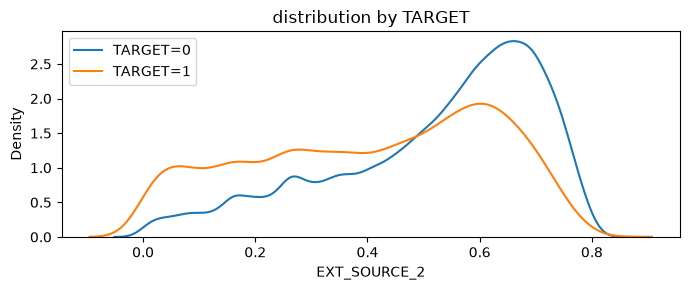

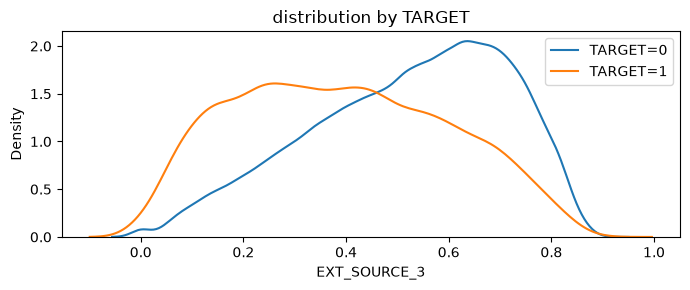

In [3]:
miss = train_raw.isna().mean().sort_values(ascending=False)
print("Top-15 missing fractions:")
print(miss.head(15).to_string())
plt.figure(figsize=(10, 4))
miss.head(20).plot(kind="bar")
plt.title("Missing-value fraction per column (train, top-20)")
plt.ylabel("fraction missing")
plt.tight_layout()
plt.show()
plt.figure(figsize=(5, 3))
sns.countplot(x=y)
plt.title("TARGET imbalance")
plt.tight_layout()
plt.show()
anio_tr = (train_raw["DAYS_EMPLOYED"] == 365243).mean()
anio_te = (test_raw["DAYS_EMPLOYED"] == 365243).mean()
print("DAYS_EMPLOYED anomaly share train:", float(anio_tr), "test:", float(anio_te))
train_plot = train_raw.copy()
train_plot["AGE_YEARS"] = -train_plot["DAYS_BIRTH"] / 365.25
plt.figure(figsize=(7, 3))
sns.histplot(train_plot["AGE_YEARS"].dropna(), bins=50, kde=True)
plt.title("AGE_YEARS overall distribution")
plt.tight_layout()
plt.show()
for c in ["EXT_SOURCE_2", "EXT_SOURCE_3"]:
    plt.figure(figsize=(7, 3))
    for tgt, lab in [(0, "TARGET=0"), (1, "TARGET=1")]:
        sns.kdeplot(train_plot.loc[train_plot["TARGET"] == tgt, c].dropna(), label=lab)
    plt.title("distribution by TARGET")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [4]:
def safe_divide(a, b):
    return a / b.replace(0, np.nan)


def add_features_v2(df):
    df = df.copy()
    if "DAYS_EMPLOYED" in df.columns:
        df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype("int8")
        df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan
    if "DAYS_BIRTH" in df.columns:
        df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
    if "DAYS_EMPLOYED" in df.columns:
        df["EMPLOYED_YEARS"] = -df["DAYS_EMPLOYED"] / 365.25
    if {"DAYS_BIRTH", "DAYS_EMPLOYED"}.issubset(df.columns):
        df["EMPLOYED_AGE_RATIO"] = safe_divide(-df["DAYS_EMPLOYED"], -df["DAYS_BIRTH"])
    if {"DAYS_REGISTRATION", "DAYS_BIRTH"}.issubset(df.columns):
        df["REGISTRATION_AGE_RATIO"] = safe_divide(-df["DAYS_REGISTRATION"], -df["DAYS_BIRTH"])
    if "DAYS_REGISTRATION" in df.columns:
        df["REGISTRATION_YEARS"] = -df["DAYS_REGISTRATION"] / 365.25
    if "DAYS_ID_PUBLISH" in df.columns:
        df["ID_DOCUMENT_YEARS"] = -df["DAYS_ID_PUBLISH"] / 365.25
    if "DAYS_LAST_PHONE_CHANGE" in df.columns:
        df["PHONE_CHANGE_YEARS"] = -df["DAYS_LAST_PHONE_CHANGE"] / 365.25
    if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["CREDIT_INCOME_RATIO"] = safe_divide(df["AMT_CREDIT"], df["AMT_INCOME_TOTAL"])
        df["INCOME_CREDIT_RATIO"] = safe_divide(df["AMT_INCOME_TOTAL"], df["AMT_CREDIT"])
    if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["ANNUITY_INCOME_RATIO"] = safe_divide(df["AMT_ANNUITY"], df["AMT_INCOME_TOTAL"])
        df["INCOME_ANNUITY_RATIO"] = safe_divide(df["AMT_INCOME_TOTAL"], df["AMT_ANNUITY"])
    if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(df.columns):
        df["CREDIT_ANNUITY_RATIO"] = safe_divide(df["AMT_CREDIT"], df["AMT_ANNUITY"])
    if {"AMT_GOODS_PRICE", "AMT_CREDIT"}.issubset(df.columns):
        df["GOODS_CREDIT_RATIO"] = safe_divide(df["AMT_GOODS_PRICE"], df["AMT_CREDIT"])
        df["CREDIT_GOODS_GAP"] = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]
    if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["INCOME_PER_FAMILY"] = safe_divide(df["AMT_INCOME_TOTAL"], df["CNT_FAM_MEMBERS"].clip(lower=1))
    if {"AMT_CREDIT", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["CREDIT_PER_FAMILY"] = safe_divide(df["AMT_CREDIT"], df["CNT_FAM_MEMBERS"].clip(lower=1))
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
    if ext:
        df["EXT_SOURCE_MEAN"] = df[ext].mean(axis=1)
        df["EXT_SOURCE_MEDIAN"] = df[ext].median(axis=1)
        df["EXT_SOURCE_MIN"] = df[ext].min(axis=1)
        df["EXT_SOURCE_MAX"] = df[ext].max(axis=1)
        df["EXT_SOURCE_RANGE"] = df[ext].max(axis=1) - df[ext].min(axis=1)
        df["EXT_SOURCE_STD"] = df[ext].std(axis=1)
        df["EXT_SOURCE_MISSING"] = df[ext].isna().sum(axis=1)
        for c in ext:
            df[c + "_SQ"] = df[c] ** 2
            df[c + "_CUBE"] = df[c] ** 3
        for i in range(len(ext)):
            for j in range(i + 1, len(ext)):
                a, b = ext[i], ext[j]
                df[a + "_" + b + "_PROD"] = df[a] * df[b]
                df[a + "_" + b + "_DIFF"] = df[a] - df[b]
                df[a + "_" + b + "_ABS_DIFF"] = (df[a] - df[b]).abs()
                df[a + "_" + b + "_RATIO"] = safe_divide(df[a], df[b])
    bureau = [c for c in df.columns if c.startswith("AMT_REQ_CREDIT_BUREAU_")]
    if bureau:
        df["BUREAU_REQUEST_TOTAL"] = df[bureau].sum(axis=1, min_count=1)
        df["BUREAU_REQUEST_MEAN"] = df[bureau].mean(axis=1)
        df["BUREAU_REQUEST_MAX"] = df[bureau].max(axis=1)
        df["BUREAU_REQUEST_MISSING"] = df[bureau].isna().sum(axis=1)
    if {"CNT_CHILDREN", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["CHILDREN_FAMILY_RATIO"] = safe_divide(df["CNT_CHILDREN"], df["CNT_FAM_MEMBERS"].clip(lower=1))
        df["ADULTS_IN_FAMILY"] = df["CNT_FAM_MEMBERS"] - df["CNT_CHILDREN"]
    contact = [c for c in ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE",
                           "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL"] if c in df.columns]
    if contact:
        df["CONTACT_FLAG_SUM"] = df[contact].sum(axis=1)
    df["TOTAL_MISSING"] = df.isna().sum(axis=1)
    df["MISSING_RATIO"] = df.isna().mean(axis=1)
    for col, new in [("AMT_INCOME_TOTAL", "LOG_AMT_INCOME_TOTAL"),
                     ("AMT_CREDIT", "LOG_AMT_CREDIT"),
                     ("AMT_ANNUITY", "LOG_AMT_ANNUITY"),
                     ("AMT_GOODS_PRICE", "LOG_AMT_GOODS_PRICE")]:
        if col in df.columns:
            df[new] = np.log1p(df[col].clip(lower=0))
    if {"AMT_ANNUITY", "AMT_CREDIT"}.issubset(df.columns):
        df["ANNUITY_CREDIT_RATE"] = safe_divide(df["AMT_ANNUITY"], df["AMT_CREDIT"])
    if {"AMT_INCOME_TOTAL", "CNT_CHILDREN"}.issubset(df.columns):
        df["INCOME_PER_CHILD"] = safe_divide(df["AMT_INCOME_TOTAL"], (df["CNT_CHILDREN"] + 1))
    if "OWN_CAR_AGE" in df.columns:
        df["OWN_CAR_MISSING"] = df["OWN_CAR_AGE"].isna().astype("int8")
        df["OWN_CAR_DECADE"] = df["OWN_CAR_AGE"] / 10.0
    if "ORGANIZATION_TYPE" in df.columns:
        df["ORG_IS_XNA"] = (df["ORGANIZATION_TYPE"] == "XNA").astype("int8")
    if {"REGION_RATING_CLIENT", "REGION_POPULATION_RELATIVE"}.issubset(df.columns):
        df["RATING_POP_INTERACT"] = df["REGION_RATING_CLIENT"] * df["REGION_POPULATION_RELATIVE"]
    df = df.replace([np.inf, -np.inf], np.nan)
    return df


def add_row_features_v2_5(df):
    df = df.copy()
    if "AGE_YEARS" in df.columns:
        df["AGE_YEARS_SQ"] = df["AGE_YEARS"] ** 2
    if "EXT_SOURCE_MEAN" in df.columns:
        df["EXT_SOURCE_MEAN_SQ"] = df["EXT_SOURCE_MEAN"] ** 2
    if {"AMT_ANNUITY", "AMT_GOODS_PRICE"}.issubset(df.columns):
        df["ANNUITY_GOODS_RATIO"] = df["AMT_ANNUITY"] / df["AMT_GOODS_PRICE"].replace(0, np.nan)
    if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS", "CNT_CHILDREN"}.issubset(df.columns):
        adults = (df["CNT_FAM_MEMBERS"] - df["CNT_CHILDREN"]).clip(lower=1)
        df["INCOME_PER_ADULT"] = df["AMT_INCOME_TOTAL"] / adults
    if "INCOME_PER_FAMILY" in df.columns:
        df["LOG_INCOME_PER_FAMILY"] = np.log1p(df["INCOME_PER_FAMILY"].clip(lower=0))
    if {"EMPLOYED_YEARS", "AGE_YEARS"}.issubset(df.columns):
        df["EMPLOYED_AGE_INTERACT"] = df["EMPLOYED_YEARS"] * df["AGE_YEARS"]
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
    if ext:
        pat = pd.Series(np.zeros(len(df), dtype="int8"), index=df.index)
        for i, c in enumerate(ext):
            pat = pat + df[c].isna().astype("int8") * (2 ** i)
        df["EXT_MISS_PATTERN"] = pat.astype("int8")
    if "BUREAU_REQUEST_TOTAL" in df.columns:
        df["BUREAU_REQUEST_ANY"] = (df["BUREAU_REQUEST_TOTAL"].fillna(0) > 0).astype("int8")
    if {"OWN_CAR_AGE", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["CAR_AGE_INCOME_INTERACT"] = df["OWN_CAR_AGE"] * df["AMT_INCOME_TOTAL"]
    df = df.replace([np.inf, -np.inf], np.nan)
    return df


def add_rank_features(X, X_test, cols):
    Xa = X.copy()
    Ta = X_test.copy()
    combined = pd.concat([Xa[cols], Ta[cols]], axis=0)
    r = combined.rank(pct=True)
    n = len(Xa)
    for c in cols:
        Xa[c + "__RANK"] = r[c].iloc[:n].to_numpy()
        Ta[c + "__RANK"] = r[c].iloc[n:].to_numpy()
    return Xa, Ta


X = add_row_features_v2_5(add_features_v2(X_raw))
X_test = add_row_features_v2_5(add_features_v2(X_test_raw)).reindex(columns=X.columns, fill_value=np.nan)
print("X:", X.shape, "X_test:", X_test.shape)
assert list(X.columns) == list(X_test.columns)
assert X.shape[0] == len(train_raw) and X_test.shape[0] == 61500
assert X.shape[1] == 103
assert not np.isinf(X.select_dtypes(include=np.number).to_numpy()).any()
X_ranked, X_test_ranked = add_rank_features(X, X_test, RANK_COLS)
assert X_ranked.shape[1] == X.shape[1] + len(RANK_COLS)
print("rank columns:", [c for c in X_ranked.columns if c.endswith("__RANK")])
print("numeric count:", len([c for c in X.columns if c not in CAT8]))


X: (171202, 103) X_test: (61500, 103)


rank columns: ['EXT_SOURCE_MEAN__RANK', 'EXT_SOURCE_MIN__RANK', 'EXT_SOURCE_MAX__RANK', 'AGE_YEARS__RANK', 'AMT_CREDIT__RANK', 'AMT_INCOME_TOTAL__RANK', 'CREDIT_INCOME_RATIO__RANK']
numeric count: 95


In [5]:
def frequency_map(train_df, other_df, cols):
    out = other_df.copy()
    for c in cols:
        m = train_df[c].value_counts(dropna=False, normalize=True)
        out[c + "__FREQ"] = other_df[c].map(m).fillna(0.0)
    return out


def target_map(train_df, y_train, other_df, cols, smoothing=60):
    out = other_df.copy()
    gm = float(np.mean(y_train))
    for c in cols:
        tmp = pd.DataFrame({"x": train_df[c].astype(object).values, "y": np.asarray(y_train)})
        st = tmp.groupby("x", dropna=False)["y"].agg(["mean", "count"])
        sm = (st["mean"] * st["count"] + gm * smoothing) / (st["count"] + smoothing)
        out[c + "__TE"] = other_df[c].map(sm).fillna(gm).astype(float)
    return out


def groupby_fit(train_df, cat_cols, num_cols):
    maps = {}
    for c in cat_cols:
        key = train_df[c].astype(object)
        g = train_df.groupby(key, dropna=False)
        for n in num_cols:
            if n in train_df.columns:
                maps[(c, n)] = (g[n].mean(), float(train_df[n].mean()))
        sizes = g.size()
        maps[(c, "__SIZE__")] = (sizes, float(sizes.mean()))
    return maps


def groupby_apply(other_df, maps, cat_cols, num_cols):
    out = other_df.copy()
    for c in cat_cols:
        key = other_df[c].astype(object)
        for n in num_cols:
            if (c, n) in maps:
                m, glob = maps[(c, n)]
                out[c + "__GB_MEAN_" + n] = key.map(m).fillna(glob).astype(float)
        m, glob = maps[(c, "__SIZE__")]
        out[c + "__GB_SIZE"] = key.map(m).fillna(glob).astype(float)
    return out


def pair_key(df, a, b):
    return df[a].astype(object).astype(str) + "||" + df[b].astype(object).astype(str)


def pair_te_fit(train_df, y_train, pairs, smoothing=60):
    gm = float(np.mean(y_train))
    maps = {}
    for ab in pairs:
        a, b = ab
        key = pair_key(train_df, a, b)
        tmp = pd.DataFrame({"k": key.values, "y": np.asarray(y_train)})
        st = tmp.groupby("k")["y"].agg(["mean", "count"])
        sm = (st["mean"] * st["count"] + gm * smoothing) / (st["count"] + smoothing)
        maps[ab] = (sm, gm)
    return maps


def pair_te_apply(other_df, maps, pairs):
    out = other_df.copy()
    for ab in pairs:
        a, b = ab
        sm, gm = maps[ab]
        key = pair_key(other_df, a, b)
        out[a + "__X__" + b + "__PTE"] = key.map(sm).fillna(gm).astype(float)
    return out


cat_cols = [c for c in CAT8 if c in X.columns]
print("encoding categoricals:", cat_cols)
assert len(cat_cols) == 8
print("smoothing:", SMOOTHING)
print("pruned groupby columns per frame:", len(PRUNE_CATS) * (len(PRUNE_NUMS) + 1))
print("pair TE columns per frame:", len(PAIRS))


encoding categoricals: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
smoothing: 60
pruned groupby columns per frame: 9
pair TE columns per frame: 2


In [6]:
t_abl = time.time()
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
splits3 = list(skf3.split(X, y))
abl_oof = {}
abl_folds = {}
for variant in ["base", "rank", "prunegb", "pair2"]:
    if variant == "rank":
        Xa, Ta = X_ranked, X_test_ranked
    else:
        Xa, Ta = X, X_test
    oof = np.zeros(len(Xa))
    fl = []
    for tr_idx, va_idx in splits3:
        X_tr = Xa.iloc[tr_idx].copy()
        X_va = Xa.iloc[va_idx].copy()
        y_tr = y.iloc[tr_idx]
        y_va = y.iloc[va_idx]
        if variant == "prunegb":
            gm = groupby_fit(X_tr, PRUNE_CATS, PRUNE_NUMS)
            X_tr = groupby_apply(X_tr, gm, PRUNE_CATS, PRUNE_NUMS)
            X_va = groupby_apply(X_va, gm, PRUNE_CATS, PRUNE_NUMS)
        if variant == "pair2":
            pm = pair_te_fit(X_tr, y_tr, PAIRS, smoothing=SMOOTHING)
            X_tr = pair_te_apply(X_tr, pm, PAIRS)
            X_va = pair_te_apply(X_va, pm, PAIRS)
        tr_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_tr, cat_cols), cat_cols, smoothing=SMOOTHING)
        va_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_va, cat_cols), cat_cols, smoothing=SMOOTHING)
        add_c = [c for c in tr_e.columns if c.endswith("__FREQ") or c.endswith("__TE")]
        tr_n = pd.concat([X_tr.drop(columns=cat_cols), tr_e[add_c]], axis=1)
        va_n = pd.concat([X_va.drop(columns=cat_cols), va_e[add_c]], axis=1)
        imp = SimpleImputer(strategy="median", add_indicator=True)
        tr_n = imp.fit_transform(tr_n)
        va_n = imp.transform(va_n)
        mdl = HistGradientBoostingClassifier(**HGB_A, random_state=SEED)
        mdl.fit(tr_n, y_tr)
        p = mdl.predict_proba(va_n)[:, 1]
        oof[va_idx] = p
        fl.append(roc_auc_score(y_va, p))
    abl_oof[variant] = oof
    abl_folds[variant] = fl
    print("ablation", variant, "folds", [round(s, 6) for s in fl], "OOF=", round(float(roc_auc_score(y, oof)), 6), flush=True)
base_oof = float(roc_auc_score(y, abl_oof["base"]))
for variant in ["rank", "prunegb", "pair2"]:
    v_oof = float(roc_auc_score(y, abl_oof[variant]))
    print("ablation DELTA", variant, "minus base =", round(v_oof - base_oof, 6), flush=True)
oof_lgb = np.zeros(len(X))
fl_lgb = []
for tr_idx, va_idx in splits3:
    X_tr = X.iloc[tr_idx].copy()
    X_va = X.iloc[va_idx].copy()
    y_tr = y.iloc[tr_idx]
    y_va = y.iloc[va_idx]
    tr_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_tr, cat_cols), cat_cols, smoothing=SMOOTHING)
    va_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_va, cat_cols), cat_cols, smoothing=SMOOTHING)
    add_c = [c for c in tr_e.columns if c.endswith("__FREQ") or c.endswith("__TE")]
    tr_n = pd.concat([X_tr.drop(columns=cat_cols), tr_e[add_c]], axis=1)
    va_n = pd.concat([X_va.drop(columns=cat_cols), va_e[add_c]], axis=1)
    mdl = lgb.LGBMClassifier(**LGBM_P, random_state=SEED)
    mdl.fit(tr_n, y_tr)
    p = mdl.predict_proba(va_n)[:, 1]
    oof_lgb[va_idx] = p
    fl_lgb.append(roc_auc_score(y_va, p))
print("ablation lgbm folds", [round(s, 6) for s in fl_lgb], "OOF=", round(float(roc_auc_score(y, oof_lgb)), 6), flush=True)
print("ablation DELTA lgbm minus base =", round(float(roc_auc_score(y, oof_lgb)) - base_oof, 6), flush=True)
print("ablation seconds:", round(time.time() - t_abl, 1))
print("kept for full run: HGB-A plus HGB-C plus LGBM on base row features with freq and smoothed TE only")


ablation base folds [0.755186, 0.754857, 0.755861] OOF= 0.755258


ablation rank folds [0.755186, 0.754857, 0.755861] OOF= 0.755258


ablation prunegb folds [0.755966, 0.754575, 0.754329] OOF= 0.754913


ablation pair2 folds [0.753815, 0.753803, 0.756155] OOF= 0.754547


ablation DELTA rank minus base = 0.0


ablation DELTA prunegb minus base = -0.000345


ablation DELTA pair2 minus base = -0.000711


ablation lgbm folds [0.758996, 0.759601, 0.75696] OOF= 0.758503


ablation DELTA lgbm minus base = 0.003245


ablation seconds: 120.9
kept for full run: HGB-A plus HGB-C plus LGBM on base row features with freq and smoothed TE only


In [7]:
t_full = time.time()
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
oof_a = np.zeros(len(X))
oof_c = np.zeros(len(X))
oof_l = np.zeros(len(X))
test_a = np.zeros(len(X_test))
test_c = np.zeros(len(X_test))
test_l = np.zeros(len(X_test))
folds_a, folds_c, folds_l = [], [], []
NS = len(SEEDS)
NF = N_SPLITS
for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    t0 = time.time()
    X_tr = X.iloc[tr_idx].copy()
    X_va = X.iloc[va_idx].copy()
    X_te = X_test.copy()
    y_tr = y.iloc[tr_idx]
    y_va = y.iloc[va_idx]
    tr_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_tr, cat_cols), cat_cols, smoothing=SMOOTHING)
    va_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_va, cat_cols), cat_cols, smoothing=SMOOTHING)
    te_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_te, cat_cols), cat_cols, smoothing=SMOOTHING)
    add_c = [c for c in tr_e.columns if c.endswith("__FREQ") or c.endswith("__TE")]
    tr_n = pd.concat([X_tr.drop(columns=cat_cols), tr_e[add_c]], axis=1)
    va_n = pd.concat([X_va.drop(columns=cat_cols), va_e[add_c]], axis=1)
    te_n = pd.concat([X_te.drop(columns=cat_cols), te_e[add_c]], axis=1)
    imp = SimpleImputer(strategy="median", add_indicator=True)
    tr_i = imp.fit_transform(tr_n)
    va_i = imp.transform(va_n)
    te_i = imp.transform(te_n)
    pa = np.zeros(len(va_idx))
    pc = np.zeros(len(va_idx))
    pl = np.zeros(len(va_idx))
    for s in SEEDS:
        m_a = HistGradientBoostingClassifier(**HGB_A, random_state=s).fit(tr_i, y_tr)
        m_c = HistGradientBoostingClassifier(**HGB_C, random_state=s).fit(tr_i, y_tr)
        m_l = lgb.LGBMClassifier(**LGBM_P, random_state=s).fit(tr_n, y_tr)
        pa = pa + m_a.predict_proba(va_i)[:, 1] / NS
        pc = pc + m_c.predict_proba(va_i)[:, 1] / NS
        pl = pl + m_l.predict_proba(va_n)[:, 1] / NS
        test_a = test_a + m_a.predict_proba(te_i)[:, 1] / (NF * NS)
        test_c = test_c + m_c.predict_proba(te_i)[:, 1] / (NF * NS)
        test_l = test_l + m_l.predict_proba(te_n)[:, 1] / (NF * NS)
    oof_a[va_idx] = pa
    oof_c[va_idx] = pc
    oof_l[va_idx] = pl
    sa = roc_auc_score(y_va, pa)
    sc = roc_auc_score(y_va, pc)
    sl = roc_auc_score(y_va, pl)
    folds_a.append(sa)
    folds_c.append(sc)
    folds_l.append(sl)
    print("fold", fold, "A=", round(float(sa), 6), "C=", round(float(sc), 6), "L=", round(float(sl), 6), "seconds=", round(time.time() - t0, 1), flush=True)
auc_a = roc_auc_score(y, oof_a)
auc_c = roc_auc_score(y, oof_c)
auc_l = roc_auc_score(y, oof_l)
print("A per-fold:", [round(float(s), 6) for s in folds_a])
print("C per-fold:", [round(float(s), 6) for s in folds_c])
print("L per-fold:", [round(float(s), 6) for s in folds_l])
print("A OOF AUC=", round(float(auc_a), 6), "C OOF AUC=", round(float(auc_c), 6), "L OOF AUC=", round(float(auc_l), 6))
print("FULL run minutes:", round((time.time() - t_full) / 60, 1))


fold 1 A= 0.755303 C= 0.755479 L= 0.757564 seconds= 140.2


fold 2 A= 0.758892 C= 0.75813 L= 0.763843 seconds= 136.6


fold 3 A= 0.762751 C= 0.762621 L= 0.766511 seconds= 152.5


fold 4 A= 0.754945 C= 0.754306 L= 0.757017 seconds= 160.1


fold 5 A= 0.758168 C= 0.757957 L= 0.762534 seconds= 149.3


A per-fold: [0.755303, 0.758892, 0.762751, 0.754945, 0.758168]
C per-fold: [0.755479, 0.75813, 0.762621, 0.754306, 0.757957]
L per-fold: [0.757564, 0.763843, 0.766511, 0.757017, 0.762534]
A OOF AUC= 0.75797 C OOF AUC= 0.757641 L OOF AUC= 0.761453
FULL run minutes: 12.3


In [8]:
print("singles: A=", round(float(auc_a), 6), "C=", round(float(auc_c), 6), "L=", round(float(auc_l), 6))
best_score = float(max(auc_a, auc_c, auc_l))
best_w = {"a": 0.0, "c": 0.0, "l": 0.0}
if auc_a >= auc_c and auc_a >= auc_l:
    best_w = {"a": 1.0, "c": 0.0, "l": 0.0}
if auc_c >= auc_a and auc_c >= auc_l:
    best_w = {"a": 0.0, "c": 1.0, "l": 0.0}
if auc_l >= auc_a and auc_l >= auc_c:
    best_w = {"a": 0.0, "c": 0.0, "l": 1.0}
pairs = [("a", "c", oof_a, oof_c), ("a", "l", oof_a, oof_l), ("c", "l", oof_c, oof_l)]
for n1, n2, o1, o2 in pairs:
    for w in np.arange(0, 1.001, 0.05):
        s = roc_auc_score(y, w * o1 + (1 - w) * o2)
        if s > best_score:
            best_score = float(s)
            best_w = {"a": 0.0, "c": 0.0, "l": 0.0}
            best_w[n1] = float(w)
            best_w[n2] = float(1 - w)
for w1 in np.arange(0, 1.001, 0.1):
    for w2 in np.arange(0, 1.001 - w1, 0.1):
        w3 = 1 - w1 - w2
        s = roc_auc_score(y, w1 * oof_a + w2 * oof_c + w3 * oof_l)
        if s > best_score:
            best_score = float(s)
            best_w = {"a": float(w1), "c": float(w2), "l": float(w3)}
print("best weights:", best_w)
print("blend OOF AUC=", round(float(best_score), 6))
final_pred = best_w["a"] * test_a + best_w["c"] * test_c + best_w["l"] * test_l
final_pred = np.clip(final_pred, 0, 1)
print("final_pred describe:")
print(pd.Series(final_pred).describe().to_string())


singles: A= 0.75797 C= 0.757641 L= 0.761453


best weights: {'a': 0.0, 'c': 0.0, 'l': 1.0}
blend OOF AUC= 0.761453
final_pred describe:
count    61500.000000
mean         0.092887
std          0.093440
min          0.002551
25%          0.030647
50%          0.060043
75%          0.119905
max          0.757258


In [9]:
output_dir = current_dir / "output"
output_dir.mkdir(exist_ok=True)
output_file = output_dir / "submission_improved_v2_6.csv"
submission = sample_sub.copy()
submission["TARGET"] = final_pred
assert submission["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
submission.to_csv(output_file, index=False, lineterminator="\n", encoding="utf-8")
print("wrote:", str(output_file))
chk = pd.read_csv(output_file)
assert list(chk.columns) == ["SK_ID_CURR", "TARGET"]
assert len(chk) == 61500
assert chk["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
assert chk["SK_ID_CURR"].equals(sample_sub["SK_ID_CURR"])
assert chk["TARGET"].isna().sum() == 0
assert ((chk["TARGET"] >= 0) & (chk["TARGET"] <= 1)).all()
raw = open(output_file, "rb").read()
assert b"\r" not in raw
assert raw.split(b"\n")[0].strip() == b"SK_ID_CURR,TARGET"
print("CSV validation passed: columns SK_ID_CURR TARGET, 61500 rows, IDs match, no NaN, probs in range 0 to 1, Unix newlines")
print(chk.head().to_string(index=False))
print(chk["TARGET"].describe().to_string())


wrote: C:\Users\sidha\Documents\visual code\Competition\output\submission_improved_v2_6.csv
CSV validation passed: columns SK_ID_CURR TARGET, 61500 rows, IDs match, no NaN, probs in range 0 to 1, Unix newlines
 SK_ID_CURR   TARGET
     171202 0.033544
     171203 0.192496
     171204 0.163797
     171205 0.116679
     171206 0.227482
count    61500.000000
mean         0.092887
std          0.093440
min          0.002551
25%          0.030647
50%          0.060043
75%          0.119905
max          0.757258
